In [1]:
print("Customer Intelligence & Churn Prevention System")
print("My Python environment is ready!")

Customer Intelligence & Churn Prevention System
My Python environment is ready!


In [2]:
import os

print("Current folder:", os.getcwd())
print("Files in current folder:", os.listdir())

Current folder: /content
Files in current folder: ['.config', 'sample_data']


In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [4]:
import zipfile

with zipfile.ZipFile("/content/archive.zip", "r") as zip_file:
    print("Files inside the ZIP:")
    for name in zip_file.namelist():
        print(name)

Files inside the ZIP:
WA_Fn-UseC_-Telco-Customer-Churn.csv


In [5]:
import zipfile

with zipfile.ZipFile("/content/archive.zip", "r") as zip_file:
    zip_file.extract(
        "WA_Fn-UseC_-Telco-Customer-Churn.csv",
        "/content"
    )

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import os

file_path = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if os.path.exists(file_path):
    print("Dataset found successfully!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("Dataset not found. Check the file location.")

Dataset found successfully!
File size: 954.59 KB


In [7]:
import pandas as pd

file_path = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("Total columns:", len(df.columns))

for column in df.columns:
    print(column)

Total columns: 21
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [9]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [10]:
print("Sample TotalCharges values:")
print(df["TotalCharges"].head(10))

print("\nData type:")
print(df["TotalCharges"].dtype)

print("\nBlank or whitespace-only values:")
print(df["TotalCharges"].str.strip().eq("").sum())


Sample TotalCharges values:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

Data type:
object

Blank or whitespace-only values:
11


In [11]:
blank_mask = df["TotalCharges"].str.strip().eq("")

print("Rows with blank TotalCharges:")
display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Rows with blank TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [12]:
import pandas as pd

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("New data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

New data type: float64
Missing values: 11


In [13]:
print("Missing values in each column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nDataset shape:", df.shape)

Missing values in each column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Number of duplicate rows: 0

Dataset shape: (7043, 21)


In [14]:
print("Missing TotalCharges by tenure:")
print(
    df.loc[df["TotalCharges"].isna(), "tenure"]
      .value_counts()
)

Missing TotalCharges by tenure:
tenure
0    11
Name: count, dtype: int64


In [15]:
print("Churn values:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [16]:
total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Churn rate:", round(churn_rate, 2), "%")

Total customers: 7043
Churned customers: 1869
Churn rate: 26.54 %


In [17]:
print("Numerical summary:")
display(df.describe())

Numerical summary:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [18]:
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn rate by contract type:")
display(contract_churn.round(2))

Churn rate by contract type:


,Churn
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


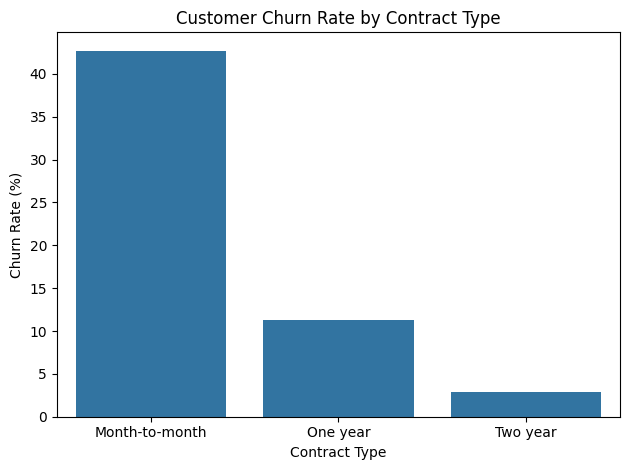

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
)

sns.barplot(data=contract_churn, x="Contract", y="ChurnRate")

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months", "25–48 months", "49–72 months"]
)

tenure_churn = df.groupby(
    "TenureGroup", observed=False
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn rate by tenure group (%):")
display(tenure_churn.round(2))

Churn rate by tenure group (%):


,Churn
TenureGroup,
0–12 months,47.44
13–24 months,28.71
25–48 months,20.39
49–72 months,9.51


In [21]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by Internet service (%):")
display(internet_churn.round(2))

Churn rate by Internet service (%):


,Churn
InternetService,
DSL,18.96
Fiber optic,41.89
No,7.40


In [22]:
print("Churn categories:")
print(df["Churn"].value_counts())

print("\nNegative tenure values:", (df["tenure"] < 0).sum())

print("\nTenure outside expected range:", (~df["tenure"].between(0, 72)).sum())

print("\nUnexpected churn values:", (~df["Churn"].isin(["Yes", "No"])).sum())

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Negative tenure values: 0

Tenure outside expected range: 0

Unexpected churn values: 0


In [23]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts().head(10))


customerID:
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
7398-LXGYX    1
1035-IPQPU    1
7203-OYKCT    1
1699-HPSBG    1
9837-FWLCH    1
Name: count, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service  

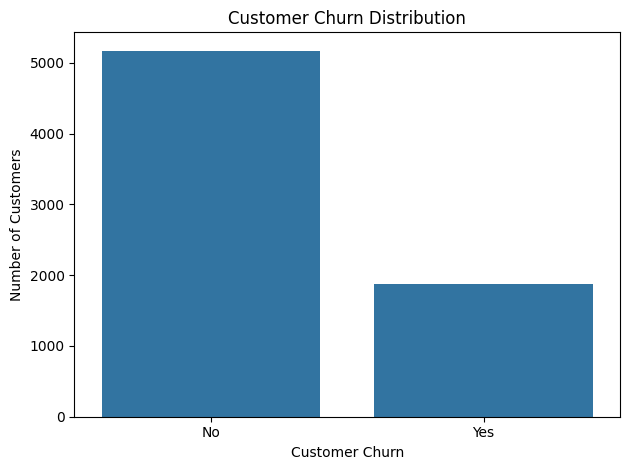

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [25]:
# Target: what we want the model to predict
y = df["Churn"]

# Features: customer information used for prediction
X = df.drop(columns=["Churn", "customerID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget categories:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (7043, 20)
Target shape: (7043,)

Target categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup']


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (5634, 20)
Testing features: (1409, 20)
Training targets: (5634,)
Testing targets: (1409,)


In [27]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training records: 5634
Testing records: 1409

Training churn distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Testing churn distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [28]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']

Number of numerical features: 4
Number of categorical features: 16


In [29]:
print("Contract categories:")
print(X_train["Contract"].value_counts())

print("\nInternet service categories:")
print(X_train["InternetService"].value_counts())

print("\nPayment method categories:")
print(X_train["PaymentMethod"].value_counts())

Contract categories:
Contract
Month-to-month    3102
Two year          1359
One year          1173
Name: count, dtype: int64

Internet service categories:
InternetService
Fiber optic    2483
DSL            1937
No             1214
Name: count, dtype: int64

Payment method categories:
PaymentMethod
Electronic check             1891
Mailed check                 1286
Bank transfer (automatic)    1244
Credit card (automatic)      1213
Name: count, dtype: int64


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each feature group
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:
# Remove identifier and derived exploration column
X = df.drop(
    columns=["Churn", "customerID", "TenureGroup"],
    errors="ignore"
)

# Target variable
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nAny customerID in features?", "customerID" in X.columns)
print("Any TenureGroup in features?", "TenureGroup" in X.columns)

Features shape: (7043, 19)
Target shape: (7043,)

Any customerID in features? False
Any TenureGroup in features? False


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining records:", len(y_train))
print("Testing records:", len(y_test))

print("\nTraining churn proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training records: 5634
Testing records: 1409

Training churn proportions:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

Testing churn proportions:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")

ValueError: A given column is not a column of the dataframe

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Identify features from the cleaned training data
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Prepare numerical columns
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline rebuilt successfully!")

Numerical features: 4
Categorical features: 15
Preprocessing pipeline rebuilt successfully!


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and the classifier
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using only the training data
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


In [36]:
# Predict churn for unseen test customers
y_pred = baseline_model.predict(X_test)

# Estimate each customer's probability of churn
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Predictions created successfully!")
print("Number of predictions:", len(y_pred))

print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob[:10].round(3))

Predictions created successfully!
Number of predictions: 1409

First 10 actual labels:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted labels:
['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No']

First 10 churn probabilities:
[0.045 0.684 0.059 0.402 0.022 0.604 0.449 0.13  0.003 0.395]


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("Precision:", round(
    precision_score(y_test, y_pred, pos_label="Yes"), 3
))

print("Recall:", round(
    recall_score(y_test, y_pred, pos_label="Yes"), 3
))

print("F1-score:", round(
    f1_score(y_test, y_pred, pos_label="Yes"), 3
))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1-score: 0.604

Detailed classification report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



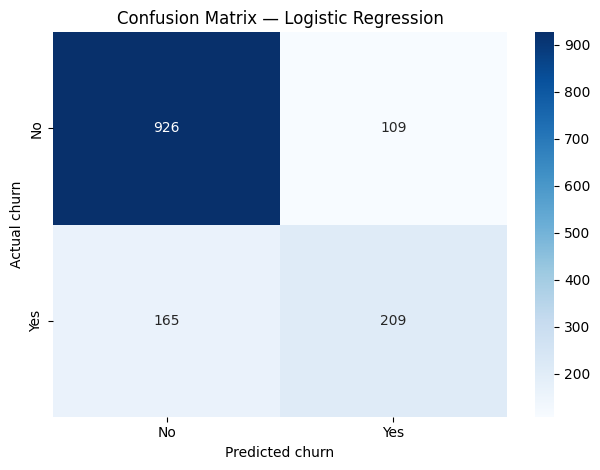

Rows = actual labels; columns = predicted labels


In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Keep the class order consistent
labels = ["No", "Yes"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted churn")
plt.ylabel("Actual churn")
plt.tight_layout()
plt.show()

print("Rows = actual labels; columns = predicted labels")

ROC-AUC: 0.842


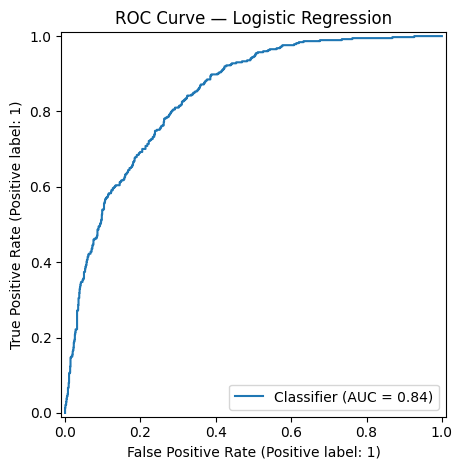

In [39]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Convert actual churn labels into binary values
y_test_binary = (y_test == "Yes").astype(int)

# Calculate ROC-AUC using predicted churn probabilities
auc_score = roc_auc_score(y_test_binary, y_prob)

print("ROC-AUC:", round(auc_score, 3))

# Plot the ROC curve
RocCurveDisplay.from_predictions(y_test_binary, y_prob)
plt.title("ROC Curve — Logistic Regression")
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

# Get the fitted preprocessing and classifier steps
fitted_preprocessor = baseline_model.named_steps["preprocessor"]
fitted_classifier = baseline_model.named_steps["classifier"]

# Retrieve feature names after encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Pair feature names with Logistic Regression coefficients
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": fitted_classifier.coef_[0]
})

# Sort by coefficient
coefficients["AbsCoefficient"] = coefficients["Coefficient"].abs()

print("Features most positively associated with churn:")
display(
    coefficients.sort_values("Coefficient", ascending=False)
    .head(10)[["Feature", "Coefficient"]]
)

print("Features most negatively associated with churn:")
display(
    coefficients.sort_values("Coefficient", ascending=True)
    .head(10)[["Feature", "Coefficient"]]
)

Features most positively associated with churn:


,Feature,Coefficient
16,cat__InternetService_Fiber optic,0.640026
36,cat__Contract_Month-to-month,0.579304
3,num__TotalCharges,0.516708
35,cat__StreamingMovies_Yes,0.204014
32,cat__StreamingTV_Yes,0.203626
43,cat__PaymentMethod_Electronic check,0.198412
18,cat__OnlineSecurity_No,0.157023
27,cat__TechSupport_No,0.132115
14,cat__MultipleLines_Yes,0.105954
0,num__SeniorCitizen,0.053929


Features most negatively associated with churn:


,Feature,Coefficient
1,num__tenure,-1.241319
38,cat__Contract_Two year,-0.772261
15,cat__InternetService_DSL,-0.652406
2,num__MonthlyCharges,-0.596392
39,cat__PaperlessBilling_No,-0.343260
22,cat__OnlineBackup_No internet service,-0.301082
25,cat__DeviceProtection_No internet service,-0.301082
28,cat__TechSupport_No internet service,-0.301082
31,cat__StreamingTV_No internet service,-0.301082
34,cat__StreamingMovies_No internet service,-0.301082


In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create a Decision Tree pipeline
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train using training data only
tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict test-set labels and churn probabilities
tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

# Convert actual labels to binary values for ROC-AUC
y_test_binary = (y_test == "Yes").astype(int)

print("Decision Tree Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print("Precision:", round(
    precision_score(y_test, tree_pred, pos_label="Yes"), 3
))
print("Recall:", round(
    recall_score(y_test, tree_pred, pos_label="Yes"), 3
))
print("F1-score:", round(
    f1_score(y_test, tree_pred, pos_label="Yes"), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_binary, tree_prob), 3
))

print("\nDetailed classification report:")
print(classification_report(y_test, tree_pred))

Decision Tree Results
---------------------
Accuracy: 0.755
Precision: 0.527
Recall: 0.759
F1-score: 0.622
ROC-AUC: 0.832

Detailed classification report:
              precision    recall  f1-score   support

          No       0.90      0.75      0.82      1035
         Yes       0.53      0.76      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [43]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Actual labels converted to binary for ROC-AUC
y_test_binary = (y_test == "Yes").astype(int)

# Collect metrics for both models
results = []

models = {
    "Logistic Regression": (baseline_model, y_pred, y_prob),
    "Decision Tree": (tree_model, tree_pred, tree_prob)
}

for name, (model, predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_binary, probabilities)
    })

comparison = pd.DataFrame(results).set_index("Model")

display(comparison.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Decision Tree,0.755,0.527,0.759,0.622,0.832


In [44]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.40, 0.50]:
    predictions = [
        "Yes" if probability >= threshold else "No"
        for probability in y_prob
    ]

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Customers flagged": sum(
            prediction == "Yes" for prediction in predictions
        )
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(3))

,Threshold,Precision,Recall,F1-score,Customers flagged
0,0.3,0.519,0.754,0.615,543
1,0.4,0.569,0.668,0.615,439
2,0.5,0.657,0.559,0.604,318


In [45]:
import pandas as pd

# Calculate churn rate by contract
contract_analysis = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
      .sort_values("ChurnRate", ascending=False)
)

# Calculate churn rate by Internet service
internet_analysis = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
      .sort_values("ChurnRate", ascending=False)
)

print("Churn rate by contract type (%):")
display(contract_analysis.round(2))

print("Churn rate by Internet service (%):")
display(internet_analysis.round(2))

Churn rate by contract type (%):


,Contract,ChurnRate
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


Churn rate by Internet service (%):


,InternetService,ChurnRate
1,Fiber optic,41.89
0,DSL,18.96
2,No,7.40


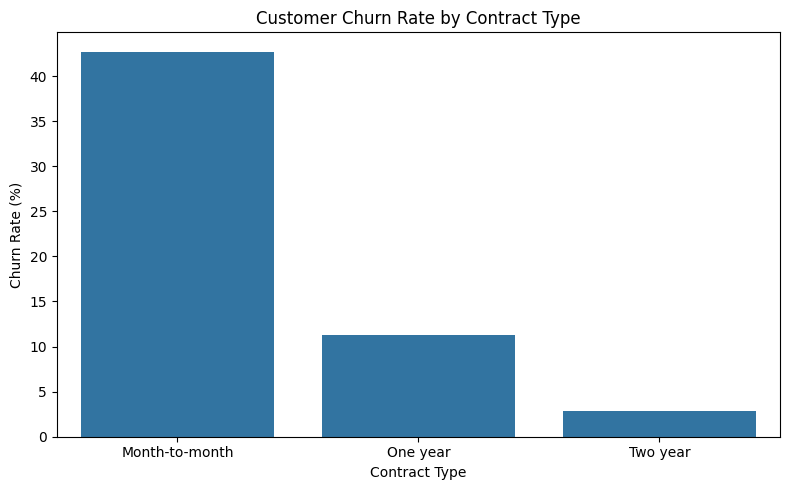

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn rate for each contract type
contract_analysis = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
      .sort_values("ChurnRate", ascending=False)
)

# Draw the chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_analysis,
    x="Contract",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

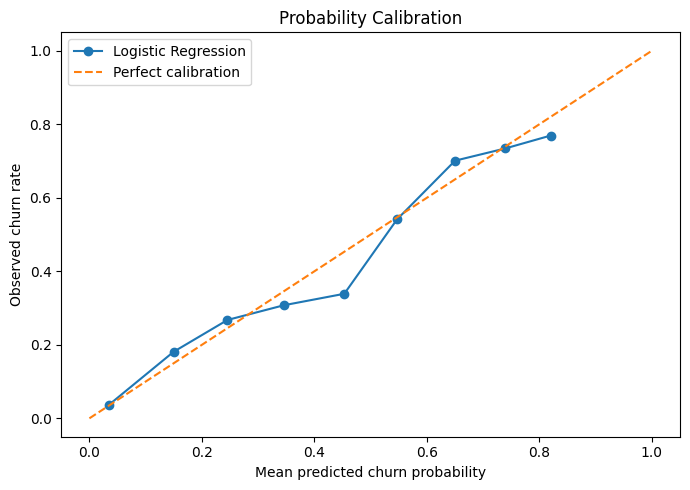

In [47]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Convert actual churn labels to binary values
y_test_binary = (y_test == "Yes").astype(int)

# Compare predicted probabilities with observed churn rates
observed_rate, mean_predicted = calibration_curve(
    y_test_binary,
    y_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))
plt.plot(mean_predicted, observed_rate, marker="o", label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted churn probability")
plt.ylabel("Observed churn rate")
plt.title("Probability Calibration")
plt.legend()
plt.tight_layout()
plt.show()

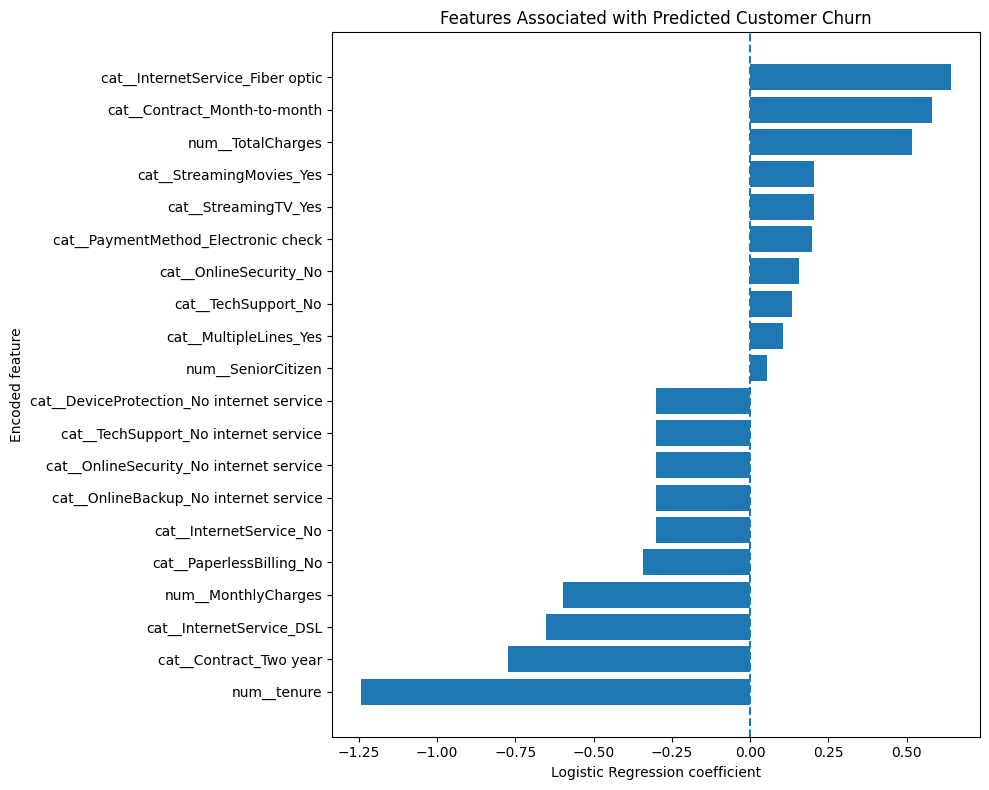

In [48]:
import matplotlib.pyplot as plt

# Select the 10 strongest positive and negative coefficients
top_positive = coefficients.nlargest(10, "Coefficient")
top_negative = coefficients.nsmallest(10, "Coefficient")

# Combine the selected features
top_features = pd.concat([top_positive, top_negative])
top_features = top_features.sort_values("Coefficient")

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Logistic Regression coefficient")
plt.ylabel("Encoded feature")
plt.title("Features Associated with Predicted Customer Churn")
plt.tight_layout()
plt.show()

In [49]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, pos_label="Yes"),
        precision_score(y_test, tree_pred, pos_label="Yes")
    ],
    "Recall": [
        recall_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, tree_pred, pos_label="Yes")
    ],
    "F1 Score": [
        f1_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, tree_pred, pos_label="Yes")
    ],
    "ROC-AUC": [
        roc_auc_score(y_test_binary, y_prob),
        roc_auc_score(y_test_binary, tree_prob)
    ]
})

results = results.round(3)
display(results)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Decision Tree,0.755,0.527,0.759,0.622,0.832


In [50]:
# Save the model comparison results as a CSV file
results.to_csv("model_comparison_results.csv", index=False)

print("Results saved successfully!")
print("File: model_comparison_results.csv")

Results saved successfully!
File: model_comparison_results.csv


In [51]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
import os

project_folder = "/content/customer-churn-project"

os.makedirs(project_folder, exist_ok=True)

print("Project folder created:", project_folder)
print("Folder exists:", os.path.exists(project_folder))

Project folder created: /content/customer-churn-project
Folder exists: True


In [53]:
import shutil
import os

source_file = "/content/model_comparison_results.csv"
destination_file = os.path.join(
    project_folder,
    "model_comparison_results.csv"
)

shutil.copy(source_file, destination_file)

print("Results copied successfully!")
print("Saved at:", destination_file)

Results copied successfully!
Saved at: /content/customer-churn-project/model_comparison_results.csv


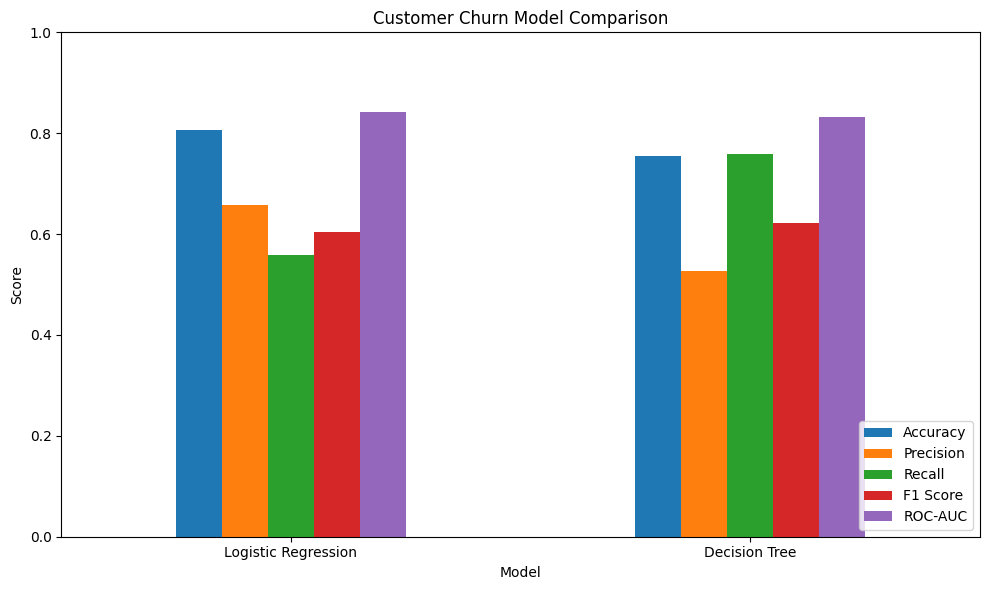

Chart saved at: /content/customer-churn-project/model_comparison.png


In [54]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Customer Churn Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

chart_path = os.path.join(
    project_folder,
    "model_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", chart_path)

In [55]:
import os

print("Project files:")

for filename in os.listdir(project_folder):
    file_path = os.path.join(project_folder, filename)
    print(f"{filename} — {os.path.getsize(file_path):,} bytes")

Project files:
model_comparison_results.csv — 143 bytes
model_comparison.png — 100,200 bytes


In [56]:
readme_content = """
# Customer Intelligence & Churn Prevention System

## Overview
This project analyzes customer data and builds machine learning
models to identify customers who may leave a telecom service.

## Dataset
IBM Telco Customer Churn dataset.
The dataset contains customer demographics, subscribed services,
account information, and churn labels.

## Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Work Completed
- Data loading and exploratory data analysis
- Missing-value investigation and preprocessing
- Categorical feature encoding
- Logistic Regression model
- Decision Tree model
- Evaluation using Accuracy, Precision, Recall, F1 Score, and ROC-AUC
- Model coefficient visualization
- Model comparison chart and results table

## Model Evaluation
See `model_comparison_results.csv` for the measured scores
and `model_comparison.png` for the comparison chart.

## Important Note
The reported metrics are based on the current test split.
Further validation is needed before real-world deployment.
Model predictions indicate associations and do not establish causation.

## Future Improvements
- Tune models and decision thresholds
- Validate performance on unseen data
- Develop customer-risk segmentation
- Build an interactive Streamlit dashboard
- Add business recommendations and deployment documentation
"""

readme_path = os.path.join(project_folder, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README created:", readme_path)
print("File exists:", os.path.exists(readme_path))

README created: /content/customer-churn-project/README.md
File exists: True


In [57]:
import shutil

zip_path = shutil.make_archive(
    "/content/customer-churn-project",
    "zip",
    project_folder
)

print("ZIP created successfully:", zip_path)

ZIP created successfully: /content/customer-churn-project.zip


In [58]:
from google.colab import files

files.download("/content/customer-churn-project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>